# Section 1 · Experiment 1：发放阈值的影响

固定恒定输入电流 2 nA，以及静息和重置电位 −65 mV、膜时间常数 20 ms、电阻 10 MΩ、不应期 2 ms、Euler 步长 0.1 ms、仿真时长 2000 ms。每组独立从静息电位开始，仅改变发放阈值。结果保存至本目录的 `results/`。


In [1]:
import sys, csv, json, platform
from pathlib import Path
from dataclasses import asdict, replace
import numpy as np
import matplotlib.pyplot as plt
import torch, snntorch
from IPython.display import display, Markdown
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'lif/model.py').is_file())
sys.path.insert(0, str(root))
from lif.model import SimulationParameters, simulate_experiment
out = root / 'lif/section1_experiment1/results'
out.mkdir(parents=True, exist_ok=True)
p = SimulationParameters(current=2.0)
thresholds = [-60, -55, -50, -47, -46, -45, -44]
metadata = {'base_parameters': asdict(p), 'thresholds_mV': thresholds, 'backend': 'snntorch', 'python': platform.python_version(), 'numpy': np.__version__, 'torch': str(torch.__version__), 'snntorch': snntorch.__version__, 'platform': platform.platform(), 'device': 'cpu'}
(out / 'parameters.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')

## 方法与理论

全程平均发放率等于实际脉冲数除以 2 秒。首个脉冲时间按仿真步末记录；未发放时留空。

恒定输入下的平衡电位为 $V_\infty=V_{rest}+RI=-45$ mV。从静息态开始，阈值低于此值时可在有限时间内达到；等于时仅渐近接近；高于时无法达到。首次达到阈值之前，连续模型的理论时间为 $-\tau_m\ln[1-(V_{th}-V_{rest})/(RI)]$。仿真使用 Euler 离散步，存在步长误差。


In [2]:
rows, traces = [], {}
for threshold in thresholds:
    data = simulate_experiment(replace(p, threshold=float(threshold)))
    traces[threshold] = data
    times = data['time_ms'][data['spikes'].astype(bool)]
    count = len(times)
    theoretical = -p.tau * np.log1p(-(threshold-p.rest)/(p.resistance*p.current)) if threshold < p.rest+p.resistance*p.current else None
    rows.append({'threshold_mV': threshold, 'spike_count': count, 'average_rate_Hz': count/(p.duration/1000), 'first_spike_ms': float(times[0]) if count else None, 'mean_ISI_ms': float(np.diff(times).mean()) if count>1 else None, 'theory_first_spike_ms': float(theoretical) if theoretical is not None else None})
    assert np.all(data['voltage'][data['spikes'].astype(bool)] == p.rest)
    if threshold >= p.rest + p.resistance*p.current: assert count == 0
    else:
        assert count > 1
        assert np.all(np.diff(times) > p.refractory)
        assert abs(times[0] - theoretical) <= p.dt + theoretical * p.dt / p.tau
    print(f'{threshold:4} mV: {count:3} spikes, {count/(p.duration/1000):5.1f} Hz; first={times[0] if count else "none"}', flush=True)
assert all(a['spike_count'] >= b['spike_count'] for a,b in zip(rows,rows[1:]))
with (out/'summary.csv').open('w', newline='', encoding='utf-8-sig') as f:
    writer=csv.DictWriter(f, fieldnames=rows[0].keys()); writer.writeheader(); writer.writerows(rows)
np.savez_compressed(out/'traces.npz', thresholds_mV=thresholds, time_ms=traces[thresholds[0]]['time_ms'], voltage_mV=np.stack([traces[t]['voltage'] for t in thresholds]), spikes=np.stack([traces[t]['spikes'] for t in thresholds]))
print('Threshold, reset, first-spike and refractory checks passed.')

 -60 mV: 256 spikes, 128.0 Hz; first=5.8
 -55 mV: 125 spikes,  62.5 Hz; first=13.9
 -50 mV:  67 spikes,  33.5 Hz; first=27.700000000000003
 -47 mV:  41 spikes,  20.5 Hz; first=46.00000000000001
 -46 mV:  32 spikes,  16.0 Hz; first=59.800000000000004
 -45 mV:   0 spikes,   0.0 Hz; first=none
 -44 mV:   0 spikes,   0.0 Hz; first=none
Threshold, reset, first-spike and refractory checks passed.


In [3]:
def fmt(v): return '—' if v is None else f'{v:.2f}'
table = '| 阈值 (mV) | Spike 总数 | 平均发放率 (Hz) | 首次发放 (ms) | 平均间隔 (ms) |\n|---:|---:|---:|---:|---:|\n' + '\n'.join(f"| {r['threshold_mV']} | {r['spike_count']} | {r['average_rate_Hz']:.1f} | {fmt(r['first_spike_ms'])} | {fmt(r['mean_ISI_ms'])} |" for r in rows)
display(Markdown(table))


| 阈值 (mV) | Spike 总数 | 平均发放率 (Hz) | 首次发放 (ms) | 平均间隔 (ms) |
|---:|---:|---:|---:|---:|
| -60 | 256 | 128.0 | 5.80 | 7.80 |
| -55 | 125 | 62.5 | 13.90 | 15.90 |
| -50 | 67 | 33.5 | 27.70 | 29.70 |
| -47 | 41 | 20.5 | 46.00 | 48.00 |
| -46 | 32 | 16.0 | 59.80 | 61.80 |
| -45 | 0 | 0.0 | — | — |
| -44 | 0 | 0.0 | — | — |

## 结果图

轨迹图展示前 300 ms，统计使用完整的 2000 ms；虚线表示每组阈值。脉冲时刻记录的电位已重置到静息值。


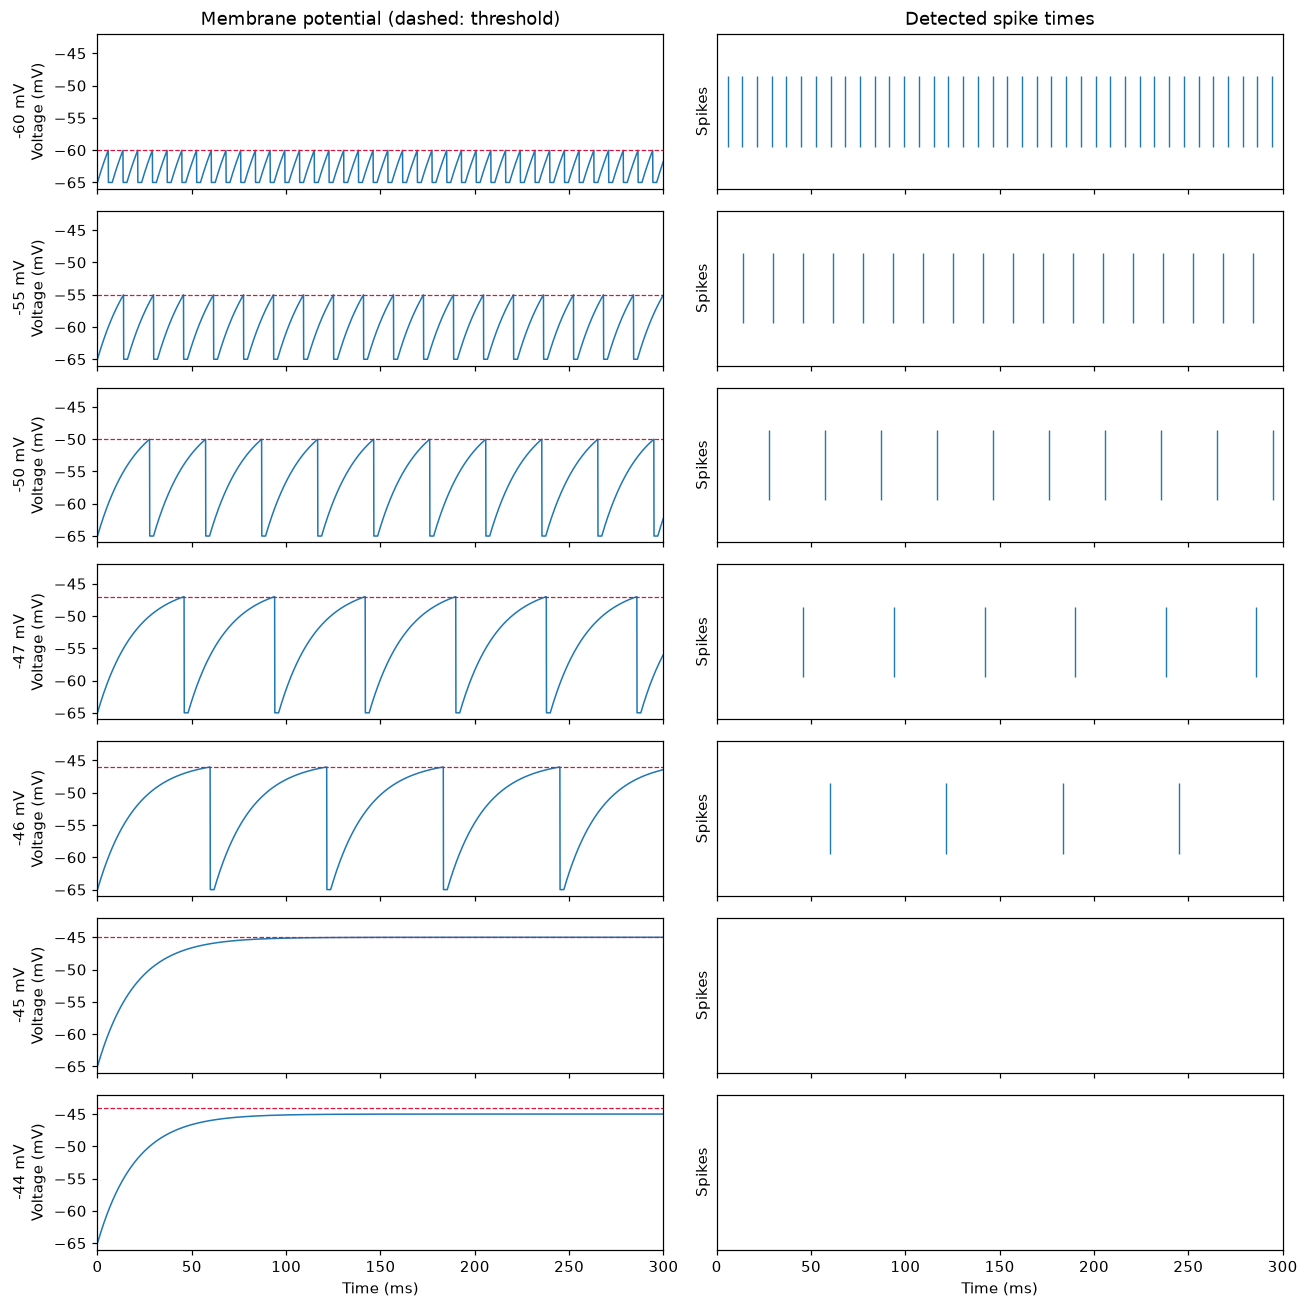

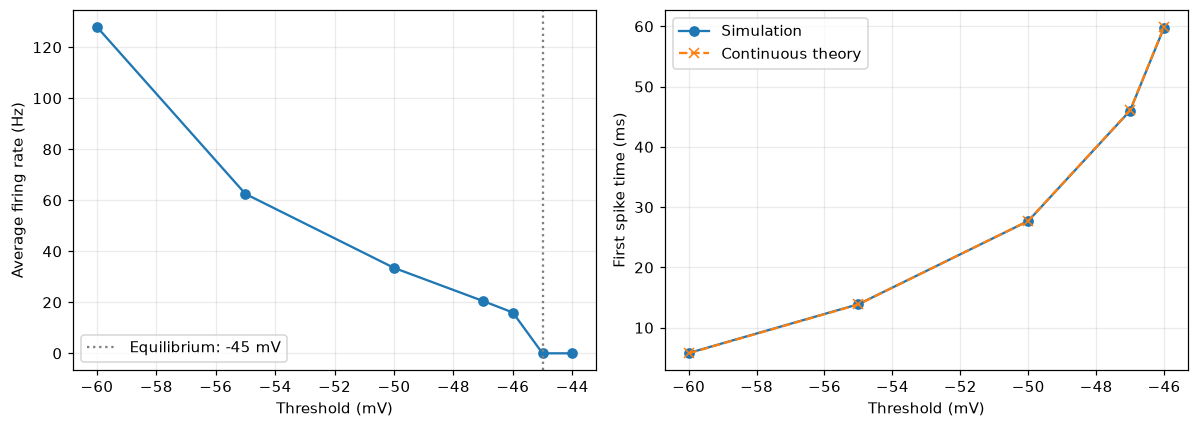

In [4]:
fig, axes=plt.subplots(len(thresholds), 2, figsize=(12, 12), sharex=True)
for i,t in enumerate(thresholds):
    d=traces[t]; keep=d['time_ms']<=300
    axes[i,0].plot(d['time_ms'][keep],d['voltage'][keep], lw=1)
    axes[i,0].axhline(t,color='crimson',ls='--',lw=.8)
    axes[i,0].set(ylabel=f'{t} mV\nVoltage (mV)',ylim=(-66,-42))
    spike_times=d['time_ms'][d['spikes'].astype(bool)]
    axes[i,1].eventplot(spike_times[spike_times<=300],linewidths=.9)
    axes[i,1].set(yticks=[],ylabel='Spikes',xlim=(0,300))
axes[0,0].set_title('Membrane potential (dashed: threshold)')
axes[0,1].set_title('Detected spike times')
for ax in axes[-1]: ax.set_xlabel('Time (ms)')
fig.tight_layout(); fig.savefig(out/'traces.png',dpi=160); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(thresholds,[r['average_rate_Hz'] for r in rows],'o-')
axes[0].axvline(-45,color='gray',ls=':',label='Equilibrium: -45 mV')
axes[0].set(xlabel='Threshold (mV)',ylabel='Average firing rate (Hz)'); axes[0].legend()
active=[r for r in rows if r['first_spike_ms'] is not None]
axes[1].plot([r['threshold_mV'] for r in active],[r['first_spike_ms'] for r in active],'o-',label='Simulation')
axes[1].plot([r['threshold_mV'] for r in active],[r['theory_first_spike_ms'] for r in active],'x--',label='Continuous theory')
axes[1].set(xlabel='Threshold (mV)',ylabel='First spike time (ms)'); axes[1].legend()
for ax in axes: ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(out/'threshold_comparison.png',dpi=180); plt.show()

In [5]:
lookup = {r['threshold_mV']: r for r in rows}
text = f"""# 阈值实验：结果与分析

保持输入 2 nA 和其他参数不变，比较 {len(thresholds)} 个阈值，每组从静息态独立仿真 2000 ms。

## 达到阈值的时间

阈值越高，膜电位需要积分得越久。−55 mV 的首次发放时间为 {lookup[-55]['first_spike_ms']:.1f} ms，−50 mV 为 {lookup[-50]['first_spike_ms']:.1f} ms，−46 mV 为 {lookup[-46]['first_spike_ms']:.1f} ms。离散步长为 0.1 ms，首发时间按步末计。

## 脉冲数量和平均发放率

−55、−50、−46 mV 分别产生 {lookup[-55]['spike_count']}、{lookup[-50]['spike_count']}、{lookup[-46]['spike_count']} 个脉冲，全程平均发放率分别为 {lookup[-55]['average_rate_Hz']:.1f}、{lookup[-50]['average_rate_Hz']:.1f}、{lookup[-46]['average_rate_Hz']:.1f} Hz。阈值升高使每次积分所需时间增加，因此发放次数及平均频率下降。

## 何时不发放？

恒定电流的平衡电位为 −65 + 10×2 = **−45 mV**。从静息电位开始，阈值高于 −45 mV 时无法达到；等于 −45 mV 时理论上只渐近接近。仿真中 −45 和 −44 mV 在 2 秒内均无脉冲。对于刚低于 −45 mV 的阈值，理论上可发放，但首次到达可能超过有限观测时长；无脉冲不一定证明永远不会发放。

## 汇总

{table}

CSV 空值表示仿真窗口内没有首次发放，或少于两次发放而无法计算间隔。图中曲线的时间均从每次独立仿真开始计。参数和软件环境见 parameters.json，完整轨迹见 traces.npz。
"""
(out / 'analysis.md').write_text(text, encoding='utf-8')
display(Markdown(text))


# 阈值实验：结果与分析

保持输入 2 nA 和其他参数不变，比较 7 个阈值，每组从静息态独立仿真 2000 ms。

## 达到阈值的时间

阈值越高，膜电位需要积分得越久。−55 mV 的首次发放时间为 13.9 ms，−50 mV 为 27.7 ms，−46 mV 为 59.8 ms。离散步长为 0.1 ms，首发时间按步末计。

## 脉冲数量和平均发放率

−55、−50、−46 mV 分别产生 125、67、32 个脉冲，全程平均发放率分别为 62.5、33.5、16.0 Hz。阈值升高使每次积分所需时间增加，因此发放次数及平均频率下降。

## 何时不发放？

恒定电流的平衡电位为 −65 + 10×2 = **−45 mV**。从静息电位开始，阈值高于 −45 mV 时无法达到；等于 −45 mV 时理论上只渐近接近。仿真中 −45 和 −44 mV 在 2 秒内均无脉冲。对于刚低于 −45 mV 的阈值，理论上可发放，但首次到达可能超过有限观测时长；无脉冲不一定证明永远不会发放。

## 汇总

| 阈值 (mV) | Spike 总数 | 平均发放率 (Hz) | 首次发放 (ms) | 平均间隔 (ms) |
|---:|---:|---:|---:|---:|
| -60 | 256 | 128.0 | 5.80 | 7.80 |
| -55 | 125 | 62.5 | 13.90 | 15.90 |
| -50 | 67 | 33.5 | 27.70 | 29.70 |
| -47 | 41 | 20.5 | 46.00 | 48.00 |
| -46 | 32 | 16.0 | 59.80 | 61.80 |
| -45 | 0 | 0.0 | — | — |
| -44 | 0 | 0.0 | — | — |

CSV 空值表示仿真窗口内没有首次发放，或少于两次发放而无法计算间隔。图中曲线的时间均从每次独立仿真开始计。参数和软件环境见 parameters.json，完整轨迹见 traces.npz。
